# EE5130: Artificial Intelligence and Machine Learning

## Hands-On Demonstration Part 2

### Recurrent Neural Networks (RNN), LSTMs, Echo-State Networks, and Autoencoders

---
### Session Objectives & Syllabus Mapping
This module continues the hands-on journey for **EE5130 (AIML)**, focusing on temporal dynamics and advanced architectures:
- **Module 5: Deep Learning & Sequential Architectures**
  - The nature of sequential data vs. static spatial data.
  - Vanilla Recurrent Neural Networks (RNN): Hidden state equations, recurrence loops.
  - Backpropagation Through Time (BPTT) and the Vanishing / Exploding Gradient Problem.
  - Gated Architectures: Long Short-Term Memory (LSTM) and Gated Recurrent Units (GRU).
  - Practical training techniques: Lookback windowing, gradient clipping, multi-step autoregression.
- **Module 3: Supervised Learning & Artificial Neural Networks (ANN)**
  - Echo-State ANN (Reservoir Computing): Fixed random recurrent dynamical systems with linear readouts.
- **Module 4: Unsupervised Learning & Neural Networks**
  - Auto Encoding Neural Networks: Latent bottlenecks, data compression, and signal reconstruction.
- **Module 11: Time Series Models**
  - Forecasting non-stationary dynamic signals.


## Importing Libraries and Setting up the Environment

In [1]:
# 1. Environment Setup & Reproducibility
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import math
import random

# Global scientific reproducibility seed
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🚀 PyTorch Version: {torch.__version__}")
print(f"⚙️ Execution Device: {device} " + (f"({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else "[CPU Mode]"))

# Visual styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11


🚀 PyTorch Version: 2.11.0+cu130
⚙️ Execution Device: cuda (Tesla T4)


---
## Section 1: Foundations of Sequential Data & Vanilla RNN Theory (Module 5 & 11)

### 1.1 Why Standard Feed-Forward Networks Fail on Sequences
1. **Variable Sequence Lengths:** Feedforward MLPs assume a fixed-dimensional input $\mathbf{x} \in \mathbb{R}^D$. Sequences vary in length (audio streams, sensor readings, text sentences).
2. **Order & Temporal Memory:** In an MLP, shuffling input order has no semantic effect once weights align. In time-series, the sequence $x_1, x_2, x_3$ carries entirely different causal meaning than $x_3, x_2, x_1$.
3. **Violated i.i.d. Assumption:** Sequential observations are statistically autocorrelated, not independently distributed.

### 1.2 The Vanilla RNN Formulation
At each time step $t$, the recurrent unit receives current input $\mathbf{x}_t$ and previous hidden state $\mathbf{h}_{t-1}$:
$$\mathbf{h}_t = \tanh\left(\mathbf{W}_{xh} \mathbf{x}_t + \mathbf{W}_{hh} \mathbf{h}_{t-1} + \mathbf{b}_h\right)$$
$$\hat{\mathbf{y}}_t = \mathbf{W}_{hy} \mathbf{h}_t + \mathbf{b}_y$$

### 1.3 Backpropagation Through Time (BPTT) & The Gradient Dilemma
During training, the loss $\mathcal{L} = \sum_{t=1}^T \mathcal{L}_t$ is backpropagated through all time steps:
$$\frac{\partial \mathcal{L}_T}{\partial \mathbf{W}_{hh}} = \sum_{k=1}^T \frac{\partial \mathcal{L}_T}{\partial \mathbf{h}_T} \frac{\partial \mathbf{h}_T}{\partial \mathbf{h}_k} \frac{\partial \mathbf{h}_k}{\partial \mathbf{W}_{hh}}$$

where the temporal chain is:
$$\frac{\partial \mathbf{h}_T}{\partial \mathbf{h}_k} = \prod_{j=k+1}^T \frac{\partial \mathbf{h}_j}{\partial \mathbf{h}_{j-1}} = \prod_{j=k+1}^T \mathbf{W}_{hh}^T \operatorname{diag}\left(1 - \tanh^2(\mathbf{z}_j)\right)$$

> **The Mathematical Dilemma:**
> - If largest eigenvalue $\lambda_{max}(\mathbf{W}_{hh}) > 1$: Gradients grow exponentially $\to$ **Exploding Gradients** (leads to `NaN` weights).
> - If largest eigenvalue $\lambda_{max}(\mathbf{W}_{hh}) < 1$ or due to $\tanh' \le 1$: Gradients shrink exponentially $\to$ **Vanishing Gradients** (network cannot learn dependencies longer than 5-10 steps!).


---
## Section 2: Gated Architectures (LSTM & GRU)

### 2.1 Long Short-Term Memory (LSTM) (Hochreiter & Schmidhuber, 1997)
The breakthrough of the LSTM is the **Cell State ($C_t$)**, an uninterrupted additive conveyor belt:

$$\begin{aligned}
\mathbf{f}_t &= \sigma\left(\mathbf{W}_f [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_f\right) && \text{[Forget Gate: What percentage of past memory to discard]} \\
\mathbf{i}_t &= \sigma\left(\mathbf{W}_i [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_i\right) && \text{[Input Gate: What fraction of candidate info to write]} \\
\tilde{\mathbf{C}}_t &= \tanh\left(\mathbf{W}_c [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_c\right) && \text{[Candidate Cell State: New information proposal]} \\
\mathbf{C}_t &= \mathbf{f}_t \odot \mathbf{C}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{C}}_t && \mathbf{[Cell State Update: ADDITIVE, prevents vanishing gradient!]} \\
\mathbf{o}_t &= \sigma\left(\mathbf{W}_o [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_o\right) && \text{[Output Gate: What part of cell state to reveal]} \\
\mathbf{h}_t &= \mathbf{o}_t \odot \tanh(\mathbf{C}_t) && \text{[Hidden State: Filtered memory emitted to next layer/step]}
\end{aligned}$$

Because $\frac{\partial \mathbf{C}_t}{\partial \mathbf{C}_{t-1}} = \mathbf{f}_t + \dots$, when the forget gate $\mathbf{f}_t \approx 1$, error gradients flow backward through time with **zero attenuation**!


📈 Telemetry Signal Synthesized:
   Total timesteps:     1200
   Lookback Window:     30 steps
   Training sequences:  819
   Validation sequences:175
   Test sequences:      176


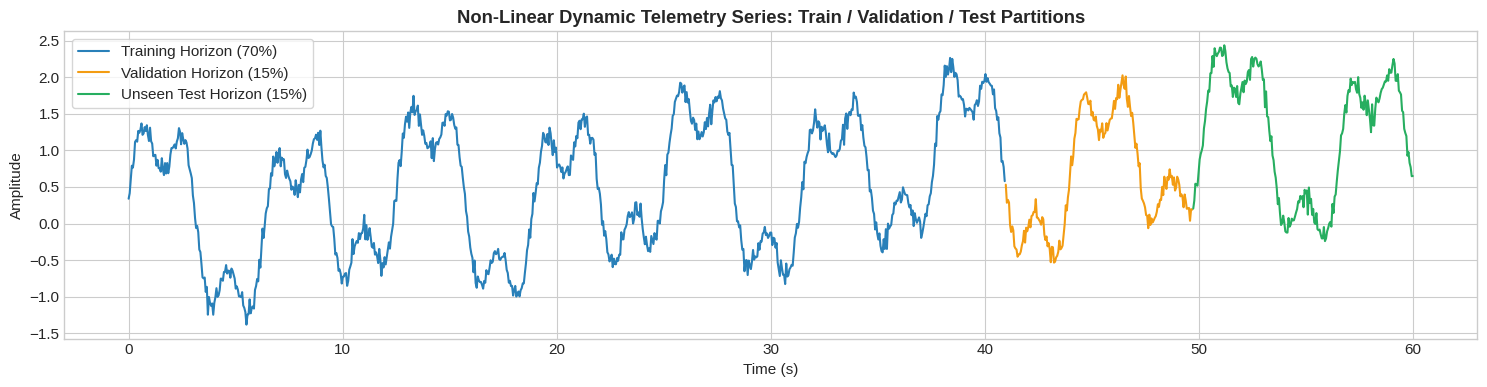

In [2]:
# 2. Sequential Telemetry Dataset Generation & Sliding Window Processing
# Simulating a realistic engineering telemetry signal (multi-harmonic oscillation + non-linear trend + noise)
N_TIMESTEPS = 1200
time_axis = np.linspace(0, 60, N_TIMESTEPS)

# Complex composite signal: Primary wave + High frequency harmonic + Non-linear slow drift
signal = (np.sin(time_axis) +
          0.5 * np.sin(3.0 * time_axis) +
          0.3 * np.cos(0.5 * time_axis) +
          0.02 * time_axis +
          0.08 * np.random.normal(size=N_TIMESTEPS))

# Normalize signal to zero mean, unit variance
signal_mean, signal_std = signal.mean(), signal.std()
signal_norm = (signal - signal_mean) / signal_std

# Lookback Windowing: Given [x_{t-T}, ..., x_{t-1}], predict x_t
WINDOW_SIZE = 30  # Lookback horizon: 30 timesteps

def create_sliding_windows(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i : i + window_size])
        y.append(data[i + window_size])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

X_all, y_all = create_sliding_windows(signal_norm, WINDOW_SIZE)
# Reshape for PyTorch RNN: [Batch, Sequence_Length, Input_Features]
X_all = np.expand_dims(X_all, axis=-1)  # Shape: (N, 30, 1)
y_all = np.expand_dims(y_all, axis=-1)  # Shape: (N, 1)

# Temporal chronological split (NO shuffling, to prevent future data leakage!)
train_split = int(0.70 * len(X_all))
val_split = int(0.85 * len(X_all))

X_train, y_train = X_all[:train_split], y_all[:train_split]
X_val, y_val = X_all[train_split:val_split], y_all[train_split:val_split]
X_test, y_test = X_all[val_split:], y_all[val_split:]

# PyTorch Dataset
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"📈 Telemetry Signal Synthesized:")
print(f"   Total timesteps:     {N_TIMESTEPS}")
print(f"   Lookback Window:     {WINDOW_SIZE} steps")
print(f"   Training sequences:  {len(train_dataset)}")
print(f"   Validation sequences:{len(val_dataset)}")
print(f"   Test sequences:      {len(test_dataset)}")

# Visualizing the raw dataset partitions
plt.figure(figsize=(15, 4))
plt.plot(time_axis[:train_split], signal[:train_split], label='Training Horizon (70%)', color='#2980b9')
plt.plot(time_axis[train_split:val_split], signal[train_split:val_split], label='Validation Horizon (15%)', color='#f39c12')
plt.plot(time_axis[val_split:len(X_all)+WINDOW_SIZE], signal[val_split:len(X_all)+WINDOW_SIZE], label='Unseen Test Horizon (15%)', color='#27ae60')
plt.title('Non-Linear Dynamic Telemetry Series: Train / Validation / Test Partitions', fontweight='bold')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


---
## Section 3: Defining Vanilla RNN vs. LSTM Side-by-Side

To conduct a fair and rigorous scientific comparison, both architectures share identical capacity:
- Input Feature Dimension: $1$
- Hidden Dimension: $48$
- Recurrent Layers: $1$
- Linear Output Projection: $48 \to 1$

### Gradient Clipping (`torch.nn.utils.clip_grad_norm_`)
To tame the exploding gradient problem endemic to recurrent networks, we apply gradient norm clipping:
$$\mathbf{g} \leftarrow \mathbf{g} \cdot \min\left(1, \frac{\text{clip\_value}}{\|\mathbf{g}\|_2}\right)$$


In [3]:
# 3. Defining Vanilla RNN and LSTM Regressors
class VanillaRNNModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=48, output_size=1):
        super(VanillaRNNModel, self).__init__()
        self.hidden_size = hidden_size
        # batch_first=True -> Input shape: [batch_size, seq_len, features]
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # rnn_out shape: [batch, seq_len, hidden_size]
        # h_n shape: [1, batch, hidden_size]
        rnn_out, h_n = self.rnn(x)
        # Take hidden state at the final time step
        last_hidden = rnn_out[:, -1, :]
        out = self.fc(last_hidden)
        return out


class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=48, output_size=1):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # lstm_out shape: [batch, seq_len, hidden_size]
        # (h_n, c_n): hidden and cell states
        lstm_out, (h_n, c_n) = self.lstm(x)
        last_hidden = lstm_out[:, -1, :]
        out = self.fc(last_hidden)
        return out

# Instantiate both models
rnn_net = VanillaRNNModel().to(device)
lstm_net = LSTMModel().to(device)

print(f"Model Architectural Specifications:")
print(f"   Vanilla RNN Parameters: {sum(p.numel() for p in rnn_net.parameters()):,}")
print(f"   LSTM Parameters:        {sum(p.numel() for p in lstm_net.parameters()):,} (4x gates = ~4x params)")


Model Architectural Specifications:
   Vanilla RNN Parameters: 2,497
   LSTM Parameters:        9,841 (4x gates = ~4x params)


---
## Section 4: Live Side-by-Side Training Pipeline & Convergence Tracking

We train both networks simultaneously across 25 epochs using:
- **Criterion:** Mean Squared Error (`nn.MSELoss()`).
- **Optimizer:** `optim.Adam(lr=0.005)`.
- **Gradient Clipping Threshold:** `1.0`.


🚀 Training Vanilla RNN vs. LSTM for 25 Epochs...
Epoch  | RNN Train MSE  | RNN Val MSE  | LSTM Train MSE  | LSTM Val MSE 
------------------------------------------------------------------------
  1    |    0.16569     |   0.02255    |     0.31807     |    0.04087   
  5    |    0.01857     |   0.01524    |     0.01668     |    0.01521   
  10   |    0.01624     |   0.01691    |     0.01579     |    0.02250   
  15   |    0.01757     |   0.01602    |     0.01615     |    0.01469   
  20   |    0.01486     |   0.01387    |     0.01797     |    0.01519   
  25   |    0.01553     |   0.01789    |     0.01575     |    0.01366   
------------------------------------------------------------------------
✅ Training Complete!


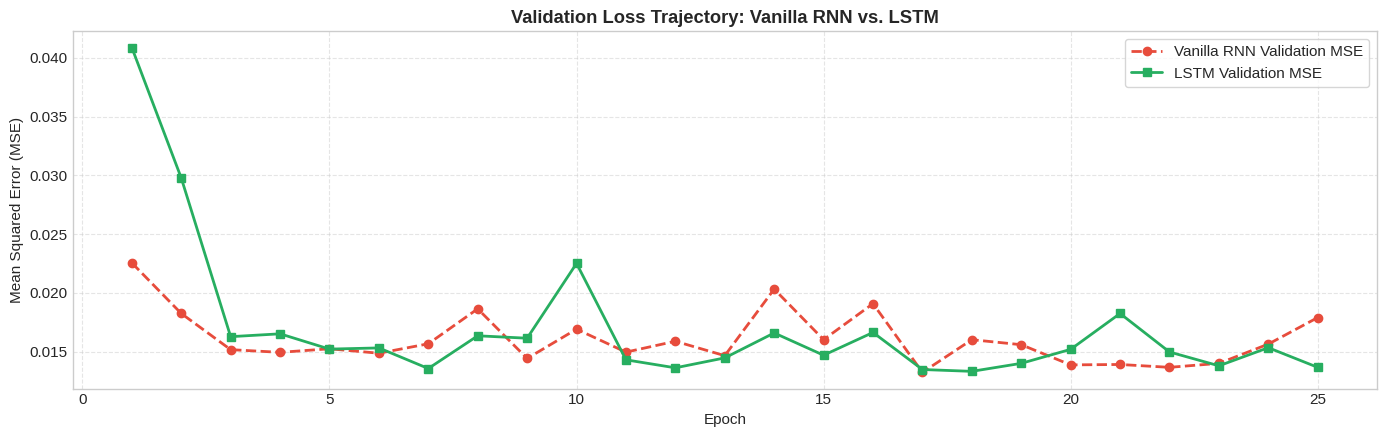

In [4]:
# 4. Simultaneous Training of Vanilla RNN and LSTM
EPOCHS = 25
LEARNING_RATE = 0.005
GRAD_CLIP = 1.0

criterion = nn.MSELoss()
opt_rnn = optim.Adam(rnn_net.parameters(), lr=LEARNING_RATE)
opt_lstm = optim.Adam(lstm_net.parameters(), lr=LEARNING_RATE)

def train_rnn_epoch(model, dataloader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    for x_batch, y_batch in dataloader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        preds = model(x_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        optimizer.step()
        total_loss += loss.item() * len(x_batch)
    return total_loss / len(dataloader.dataset)

def eval_rnn(model, dataloader, criterion):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for x_batch, y_batch in dataloader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            preds = model(x_batch)
            loss = criterion(preds, y_batch)
            total_loss += loss.item() * len(x_batch)
    return total_loss / len(dataloader.dataset)

history_rnn = {'train': [], 'val': []}
history_lstm = {'train': [], 'val': []}

print(f"🚀 Training Vanilla RNN vs. LSTM for {EPOCHS} Epochs...")
print(f"{'Epoch':^6} | {'RNN Train MSE':^14} | {'RNN Val MSE':^12} | {'LSTM Train MSE':^15} | {'LSTM Val MSE':^13}")
print("-" * 72)

for epoch in range(1, EPOCHS + 1):
    # Train and evaluate RNN
    r_tr = train_rnn_epoch(rnn_net, train_loader, opt_rnn, criterion)
    r_val = eval_rnn(rnn_net, val_loader, criterion)
    history_rnn['train'].append(r_tr)
    history_rnn['val'].append(r_val)

    # Train and evaluate LSTM
    l_tr = train_rnn_epoch(lstm_net, train_loader, opt_lstm, criterion)
    l_val = eval_rnn(lstm_net, val_loader, criterion)
    history_lstm['train'].append(l_tr)
    history_lstm['val'].append(l_val)

    if epoch % 5 == 0 or epoch == 1:
        print(f"{epoch:^6} | {r_tr:^14.5f} | {r_val:^12.5f} | {l_tr:^15.5f} | {l_val:^13.5f}")

print("-" * 72)
print("✅ Training Complete!")

# Plot Learning Curves
plt.figure(figsize=(14, 4.5))
epochs_rng = range(1, EPOCHS + 1)
plt.plot(epochs_rng, history_rnn['val'], 'o--', color='#e74c3c', label='Vanilla RNN Validation MSE', linewidth=2)
plt.plot(epochs_rng, history_lstm['val'], 's-', color='#27ae60', label='LSTM Validation MSE', linewidth=2)
plt.title('Validation Loss Trajectory: Vanilla RNN vs. LSTM', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


---
## Section 5: Unseen Horizon Testing & Multi-Step Autoregressive Rollout

### 5.1 One-Step Ahead Testing
We compare the predictions of both models on the completely unseen test sequence ($15\%$ of telemetry horizon).

### 5.2 Autoregressive Multi-Step Rollout (Simulating the Real World)
In industrial operations (e.g., smart grid power dispatch), true future inputs are **unknown**. The model must make a prediction, append its own prediction to the input window, discard the oldest observation, and roll forward iteratively!


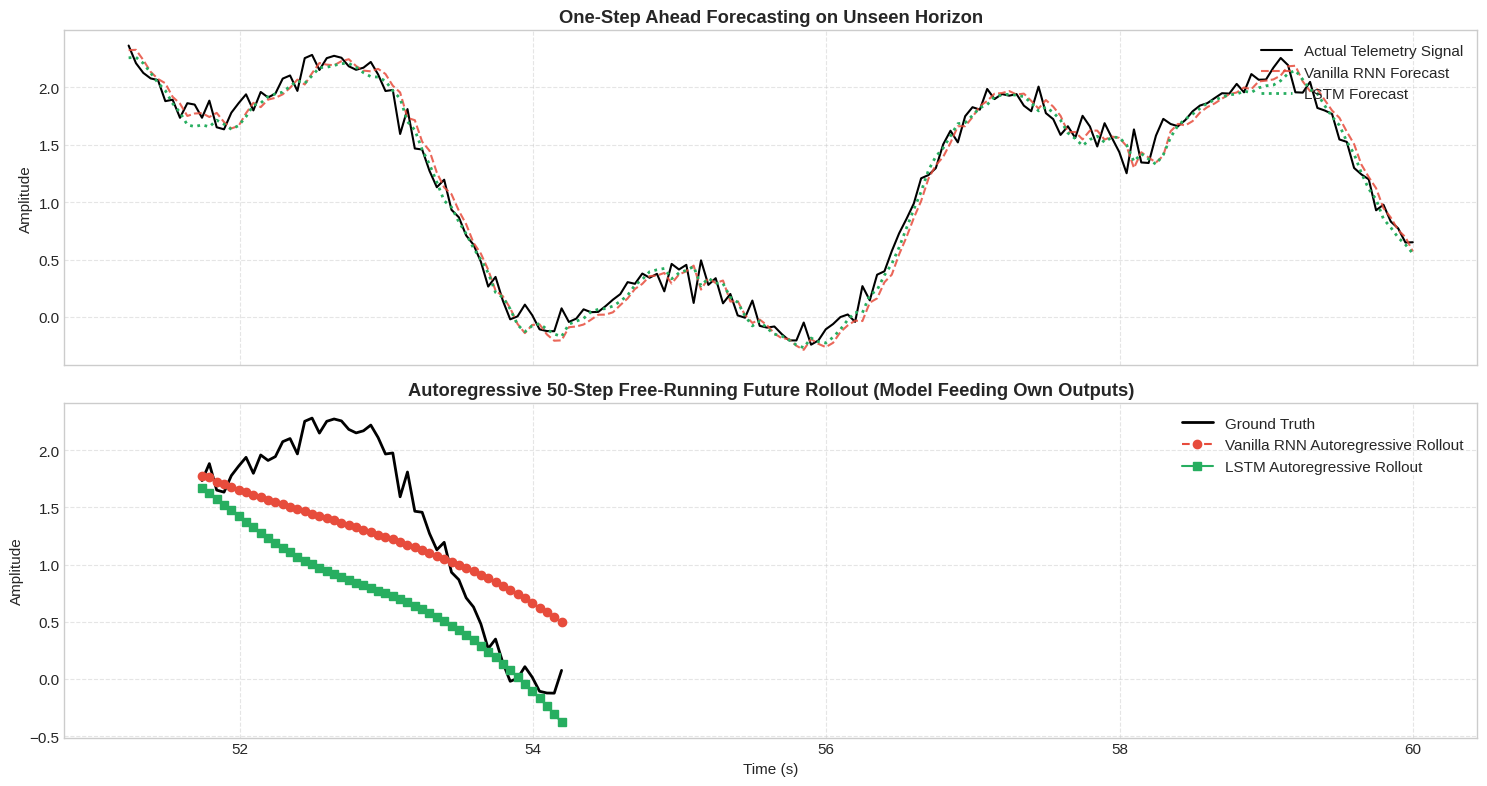

📊 Quantitative Test Evaluation:
   Vanilla RNN Test MSE: 0.01546
   LSTM Test MSE:        0.01262 (Error reduction: 18.4%)


In [5]:
# 5. One-Step and Multi-Step Forecasting on Unseen Horizon
rnn_net.eval()
lstm_net.eval()

with torch.no_grad():
    x_test_torch = torch.from_numpy(X_test).to(device)
    preds_rnn_norm = rnn_net(x_test_torch).cpu().numpy().squeeze()
    preds_lstm_norm = lstm_net(x_test_torch).cpu().numpy().squeeze()

# Denormalize predictions back to physical units
preds_rnn = preds_rnn_norm * signal_std + signal_mean
preds_lstm = preds_lstm_norm * signal_std + signal_mean
ground_truth = y_test.squeeze() * signal_std + signal_mean

test_time = time_axis[val_split + WINDOW_SIZE : val_split + WINDOW_SIZE + len(ground_truth)]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Plot 1: Full Test Horizon One-Step Forecast
ax1.plot(test_time, ground_truth, color='black', linewidth=1.5, label='Actual Telemetry Signal')
ax1.plot(test_time, preds_rnn, '--', color='#e74c3c', alpha=0.85, label='Vanilla RNN Forecast')
ax1.plot(test_time, preds_lstm, ':', color='#27ae60', linewidth=2.0, label='LSTM Forecast')
ax1.set_title('One-Step Ahead Forecasting on Unseen Horizon', fontweight='bold')
ax1.set_ylabel('Amplitude')
ax1.legend(loc='upper right')
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Autoregressive Multi-Step Rollout (40 Steps into the Future)
ROLLOUT_STEPS = 50
start_idx = 10
rollout_window_rnn = X_test[start_idx:start_idx+1].copy() # [1, 30, 1]
rollout_window_lstm = X_test[start_idx:start_idx+1].copy()

rollout_preds_rnn = []
rollout_preds_lstm = []

for _ in range(ROLLOUT_STEPS):
    with torch.no_grad():
        p_r = rnn_net(torch.from_numpy(rollout_window_rnn).to(device)).cpu().numpy()[0, 0]
        p_l = lstm_net(torch.from_numpy(rollout_window_lstm).to(device)).cpu().numpy()[0, 0]

        rollout_preds_rnn.append(p_r)
        rollout_preds_lstm.append(p_l)

        # Slide window: append prediction, drop oldest
        rollout_window_rnn = np.roll(rollout_window_rnn, -1, axis=1)
        rollout_window_rnn[0, -1, 0] = p_r

        rollout_window_lstm = np.roll(rollout_window_lstm, -1, axis=1)
        rollout_window_lstm[0, -1, 0] = p_l

rollout_preds_rnn = np.array(rollout_preds_rnn) * signal_std + signal_mean
rollout_preds_lstm = np.array(rollout_preds_lstm) * signal_std + signal_mean
rollout_true = ground_truth[start_idx : start_idx + ROLLOUT_STEPS]
rollout_time = test_time[start_idx : start_idx + ROLLOUT_STEPS]

ax2.plot(rollout_time, rollout_true, 'k-', linewidth=2.0, label='Ground Truth')
ax2.plot(rollout_time, rollout_preds_rnn, 'o--', color='#e74c3c', label='Vanilla RNN Autoregressive Rollout')
ax2.plot(rollout_time, rollout_preds_lstm, 's-', color='#27ae60', label='LSTM Autoregressive Rollout')
ax2.set_title('Autoregressive 50-Step Free-Running Future Rollout (Model Feeding Own Outputs)', fontweight='bold')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Amplitude')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Quantitative Metrics
mse_rnn = np.mean((ground_truth - preds_rnn)**2)
mse_lstm = np.mean((ground_truth - preds_lstm)**2)
print(f"📊 Quantitative Test Evaluation:")
print(f"   Vanilla RNN Test MSE: {mse_rnn:.5f}")
print(f"   LSTM Test MSE:        {mse_lstm:.5f} (Error reduction: {(1 - mse_lstm/mse_rnn)*100:.1f}%)")


---
## Section 6: Syllabus Touchpoint 1 - Echo-State ANN / Reservoir Computing (Module 3)

In Module 3 of the syllabus, **Echo-State Artificial Neural Networks (ESN)** are explicitly highlighted.

### What is an Echo-State Network (Jaeger, 2001)?
Instead of training all recurrent weights via expensive backpropagation through time (BPTT), ESNs take a radical departure called **Reservoir Computing**:
1. **The Reservoir ($W_{res}$):** A large, sparse, random recurrent network of $N$ non-linear neurons ($N=100-500$).
2. **Fixed Random Weights:** Input weights $\mathbf{W}_{in}$ and reservoir weights $\mathbf{W}_{res}$ are initialized randomly and **NEVER updated**!
3. **Echo State Property:** The reservoir matrix is scaled such that its spectral radius (largest absolute eigenvalue) is strictly less than 1:
   $$\rho(\mathbf{W}_{res}) < 1$$
   This guarantees that past input perturbations wash out asymptotically (the system has fading memory).
4. **Instantaneous Closed-Form Training:** Only the **linear readout matrix** $\mathbf{W}_{out}$ is trained, computed instantaneously using Ridge Regression:
   $$\mathbf{W}_{out} = \mathbf{Y}_{target} \mathbf{S}^T \left(\mathbf{S} \mathbf{S}^T + \alpha \mathbf{I}\right)^{-1}$$

> **Key Advantage:** Training takes **0.01 seconds** with zero gradient vanishing or explosion!


⚡ Echo-State ANN (Reservoir Computing) Results:
   Reservoir Neurons: 120
   Training Time:     0.2574 seconds (Near-instantaneous closed-form!)
   Test MSE:          0.01301


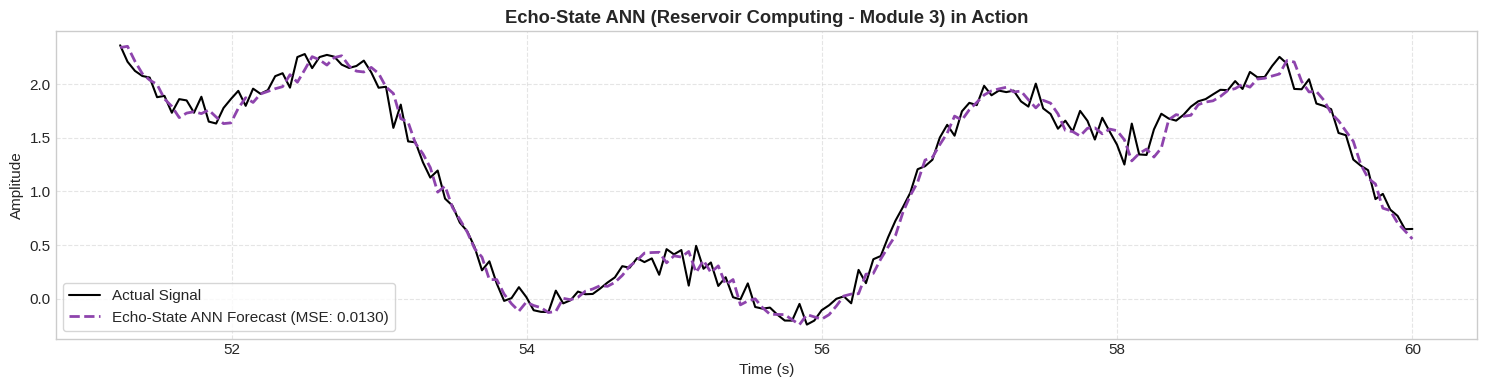

In [6]:
# 6. Implementing and Evaluating an Echo-State Network (ESN)
class EchoStateNetwork:
    def __init__(self, n_inputs=1, n_reservoir=120, spectral_radius=0.95, sparsity=0.2, alpha=1e-3):
        self.n_inputs = n_inputs
        self.n_reservoir = n_reservoir
        self.alpha = alpha  # Ridge regularization

        # 1. Random input projection weights W_in ~ Uniform(-0.5, 0.5)
        self.W_in = np.random.uniform(-0.5, 0.5, (n_reservoir, n_inputs))

        # 2. Random sparse reservoir weights W_res
        W = np.random.uniform(-1.0, 1.0, (n_reservoir, n_reservoir))
        mask = np.random.rand(n_reservoir, n_reservoir) < sparsity
        W = W * mask

        # 3. Scale to satisfy the Echo-State Property: rho(W_res) < 1
        eigenvalues = np.linalg.eigvals(W)
        current_radius = np.max(np.abs(eigenvalues))
        if current_radius > 0:
            self.W_res = W * (spectral_radius / current_radius)
        else:
            self.W_res = W

        self.W_out = None

    def _harvest_states(self, X_seqs):
        """Runs inputs through the dynamic reservoir and collects internal states."""
        all_states = []
        for seq in X_seqs:
            state = np.zeros(self.n_reservoir)
            for t in range(seq.shape[0]):
                u_t = seq[t]
                # Dynamic state equation: s_t = tanh(W_in * u_t + W_res * s_{t-1})
                state = np.tanh(np.dot(self.W_in, u_t) + np.dot(self.W_res, state))
            all_states.append(state)
        return np.array(all_states)

    def fit(self, X_seqs, y_targets):
        """Instantaneous closed-form Ridge Regression fit."""
        S = self._harvest_states(X_seqs) # State matrix: [N_samples, n_reservoir]
        # Solve W_out * S^T = y -> W_out = y * S * (S^T * S + alpha * I)^(-1)
        reg_eye = self.alpha * np.eye(self.n_reservoir)
        self.W_out = np.dot(y_targets.T, np.dot(S, np.linalg.inv(np.dot(S.T, S) + reg_eye)))

    def predict(self, X_seqs):
        S = self._harvest_states(X_seqs)
        return np.dot(S, self.W_out.T)

# Train the ESN live!
t0 = time.time()
esn = EchoStateNetwork(n_inputs=1, n_reservoir=120, spectral_radius=0.92, alpha=1e-3)
esn.fit(X_train, y_train)
esn_fit_time = time.time() - t0

# Evaluate on test set
preds_esn_norm = esn.predict(X_test)
preds_esn = preds_esn_norm.squeeze() * signal_std + signal_mean
mse_esn = np.mean((ground_truth - preds_esn)**2)

print(f"⚡ Echo-State ANN (Reservoir Computing) Results:")
print(f"   Reservoir Neurons: {esn.n_reservoir}")
print(f"   Training Time:     {esn_fit_time:.4f} seconds (Near-instantaneous closed-form!)")
print(f"   Test MSE:          {mse_esn:.5f}")

# Plotting ESN prediction against Actual
plt.figure(figsize=(15, 4))
plt.plot(test_time, ground_truth, 'k-', label='Actual Signal', linewidth=1.5)
plt.plot(test_time, preds_esn, '--', color='#8e44ad', label=f'Echo-State ANN Forecast (MSE: {mse_esn:.4f})', linewidth=2)
plt.title('Echo-State ANN (Reservoir Computing - Module 3) in Action', fontweight='bold')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


---
## Section 7: Syllabus Touchpoint 2 - Auto Encoding Neural Networks (Module 4)

In Module 4 of the syllabus, **Auto Encoding Neural Networks (Autoencoders)** represent the cornerstone of unsupervised deep representation learning.

### Structure of an Autoencoder:
1. **Encoder ($f_\theta$):** Maps high-dimensional input $\mathbf{x} \in \mathbb{R}^D$ down to a compact bottleneck latent code $\mathbf{z} \in \mathbb{R}^d$ (where $d \ll D$):
   $$\mathbf{z} = \sigma(\mathbf{W}_e \mathbf{x} + \mathbf{b}_e)$$
2. **Decoder ($g_\phi$):** Reconstructs the original input from the compressed latent code:
   $$\hat{\mathbf{x}} = \sigma(\mathbf{W}_d \mathbf{z} + \mathbf{b}_d)$$
3. **Objective:** Minimize Reconstruction Mean Squared Error:
   $$\mathcal{L}(\mathbf{x}, \hat{\mathbf{x}}) = \frac{1}{D} \sum_{i=1}^D (x_i - \hat{x}_i)^2$$

### Applications:
- Non-linear Dimensionality Reduction (superior to PCA).
- Signal Denoising (learning true manifold while stripping orthogonal noise).
- Anomaly Detection (high reconstruction error indicates novel out-of-distribution patterns).


Training Unsupervised Autoencoder (15 Epochs)...


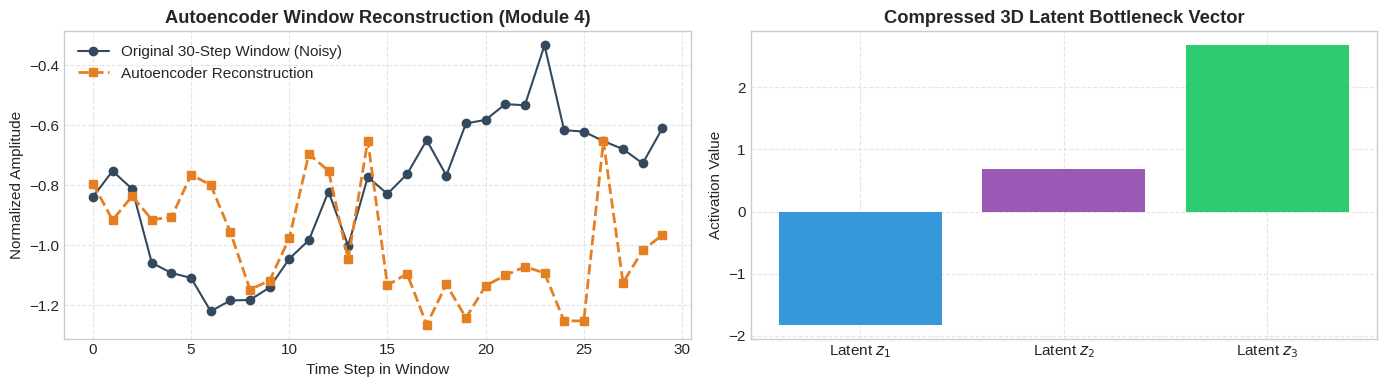

✅ Autoencoder achieved 10x Compression (30 -> 3 dimensions) while preserving waveform topology!


In [7]:
# 7. Unsupervised Representation Learning: Autoencoder on Windowed Sequences
class TemporalAutoencoder(nn.Module):
    def __init__(self, input_dim=30, latent_dim=3):
        super(TemporalAutoencoder, self).__init__()
        # Encoder: 30 -> 16 -> 3 (Compressed Latent Bottleneck)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.Tanh(),
            nn.Linear(16, latent_dim)
        )
        # Decoder: 3 -> 16 -> 30 (Reconstruction)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.Tanh(),
            nn.Linear(16, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon, z

# Prepare windowed dataset for unsupervised reconstruction
X_flat_train = torch.from_numpy(X_train.squeeze(-1)).to(device)
X_flat_val = torch.from_numpy(X_val.squeeze(-1)).to(device)

ae_model = TemporalAutoencoder(input_dim=WINDOW_SIZE, latent_dim=3).to(device)
ae_optimizer = optim.Adam(ae_model.parameters(), lr=0.008)
ae_criterion = nn.MSELoss()

print("Training Unsupervised Autoencoder (15 Epochs)...")
for epoch in range(15):
    ae_model.train()
    ae_optimizer.zero_grad()
    recon, _ = ae_model(X_flat_train)
    loss = ae_criterion(recon, X_flat_train)
    loss.backward()
    ae_optimizer.step()

ae_model.eval()
with torch.no_grad():
    sample_window = X_flat_val[5:6]
    recon_window, latent_z = ae_model(sample_window)

sample_orig = sample_window.cpu().numpy().squeeze()
sample_recon = recon_window.cpu().numpy().squeeze()
z_val = latent_z.cpu().numpy().squeeze()

# Visualizing Reconstruction and Latent Bottleneck
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(sample_orig, 'o-', color='#34495e', label='Original 30-Step Window (Noisy)')
ax1.plot(sample_recon, 's--', color='#e67e22', linewidth=2, label='Autoencoder Reconstruction')
ax1.set_title('Autoencoder Window Reconstruction (Module 4)', fontweight='bold')
ax1.set_xlabel('Time Step in Window')
ax1.set_ylabel('Normalized Amplitude')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.bar(['Latent $z_1$', 'Latent $z_2$', 'Latent $z_3$'], z_val, color=['#3498db', '#9b59b6', '#2ecc71'])
ax2.set_title('Compressed 3D Latent Bottleneck Vector', fontweight='bold')
ax2.set_ylabel('Activation Value')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"✅ Autoencoder achieved 10x Compression (30 -> 3 dimensions) while preserving waveform topology!")
